Siddhant Bhalerao

B B3 43

ML Practical-2

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df=pd.read_csv('USA_Housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64,6.00,6.73,3.09,40173.07,1505890.91,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81,USS Barnett\nFPO AP 44820
4,59982.20,5.04,7.84,4.23,26354.11,630943.49,USNS Raymond\nFPO AE 09386


In [33]:
df.tail()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
4995,60567.94,7.83,6.14,3.46,22837.36,1060193.79,USNS Williams\nFPO AP 30153-7653
4996,78491.28,7.00,6.58,4.02,25616.12,1482617.73,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.69,7.25,4.81,2.13,33266.15,1030729.58,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.33,5.53,7.13,5.44,42625.62,1198656.87,USS Wallace\nFPO AE 73316
4999,65510.58,5.99,6.79,4.07,46501.28,1298950.48,"37778 George Ridges Apt. 509\nEast Holly, NV 2..."


In [35]:
print(df.shape)

(5000, 7)


In [37]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,68583.11,5.98,6.99,3.98,36163.52,1232072.65
std,10657.99,0.99,1.01,1.23,9925.65,353117.63
min,17796.63,2.64,3.24,2.00,172.61,15938.66
25%,61480.56,5.32,6.30,3.14,29403.93,997577.14
50%,68804.29,5.97,7.00,4.05,36199.41,1232669.38
75%,75783.34,6.65,7.67,4.49,42861.29,1471210.20
max,107701.75,9.52,10.76,6.50,69621.71,2469065.59


In [39]:
pd.set_option('display.float_format','{:.2f}'.format)

In [41]:
df.drop("Address",axis=1,inplace=True)

In [43]:
print(df.shape)

(5000, 6)


In [45]:
df.isnull().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
dtype: int64

In [49]:
df.duplicated().sum()

0

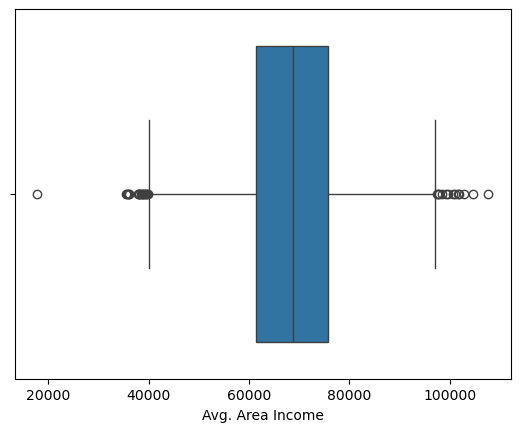

In [47]:
sns.boxplot(x=df["Avg. Area Income"])
plt.show()

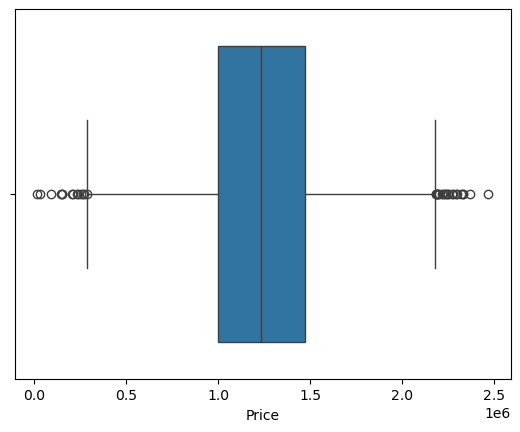

In [55]:
sns.boxplot(x=df["Price"])
plt.show()

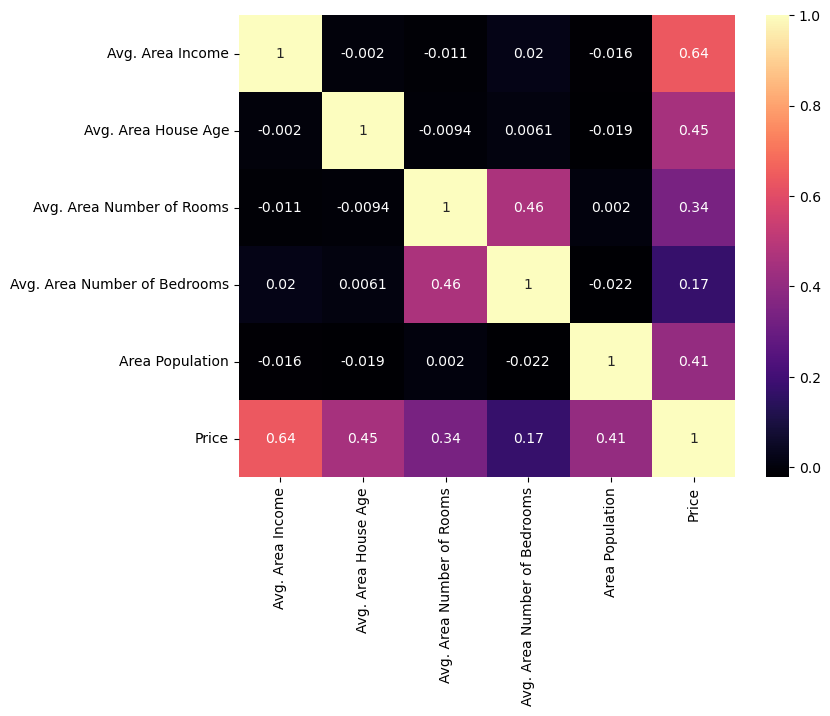

In [53]:
plt.figure(figsize=(8,6))
numeric_df=df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='magma')
plt.show()

In [63]:
Q1=df["Avg. Area Income"].quantile(0.25)
Q3=df["Avg. Area Income"].quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

df=df[(df["Avg. Area Income"]>=lower)&(df["Avg. Area Income"] <=upper)]

In [65]:
Q1=df["Price"].quantile(0.25)
Q3=df["Price"].quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

df=df[(df["Price"]>=lower)&(df["Price"] <=upper)]

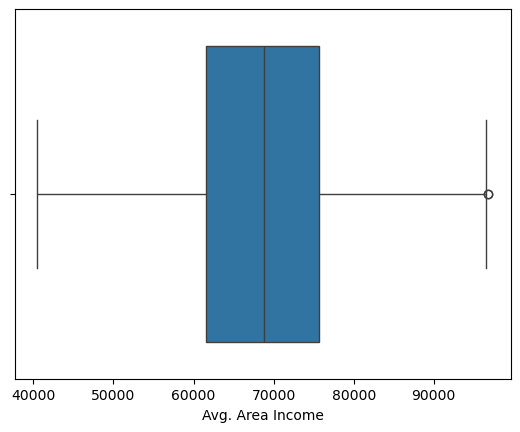

In [67]:
sns.boxplot(x=df["Avg. Area Income"])
plt.show()

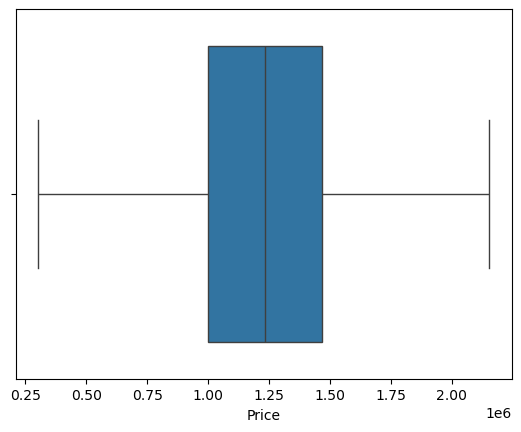

In [69]:
sns.boxplot(x=df["Price"])
plt.show()

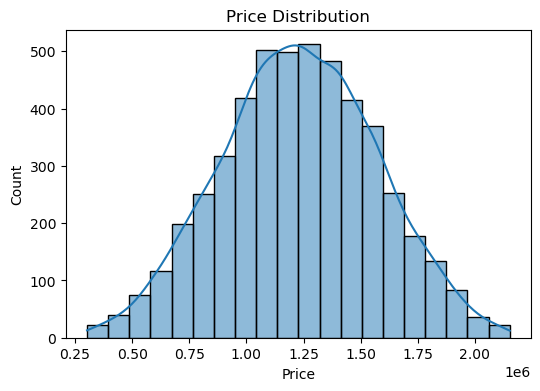

In [71]:
plt.figure(figsize=(6,4))
sns.histplot(df["Price"],bins=20,kde=True)

plt.title("Price Distribution")
plt.show()

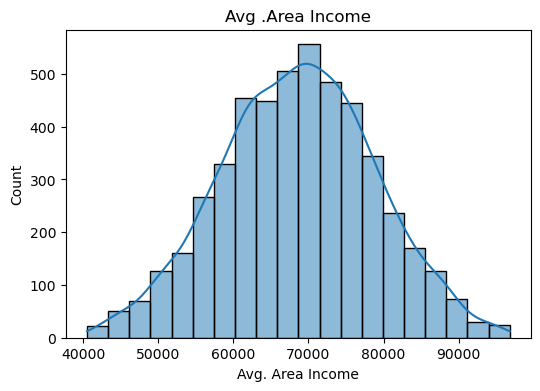

In [73]:
plt.figure(figsize=(6,4))
sns.histplot(df["Avg. Area Income"],bins=20,kde=True)

plt.title("Avg .Area Income")
plt.show()

SLR

In [89]:
X=df[['Avg. Area Income']]
y=df[['Price']]

In [91]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [93]:
from sklearn.linear_model import LinearRegression

slr_model=LinearRegression()
slr_model.fit(X_train, y_train)

LinearRegression()

In [96]:
y_pred=slr_model.predict(X_test)

In [98]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [100]:
print("Simple Linear Regression Results")
print("--------------------------------")

print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("RMSE:",np.sqrt(mean_absolute_error(y_test,y_pred)))
print("R^2 Score:",r2_score(y_test,y_pred))

Simple Linear Regression Results
--------------------------------
MAE: 217702.8077622295
MSE: 73955274572.97168
RMSE: 466.58633473584445
R^2 Score: 0.36616766178023674


In [102]:
print("Intercept:",slr_model.intercept_)
print("Slope:",slr_model.coef_[0])

Intercept: [-162150.25245191]
Slope: [20.34935404]


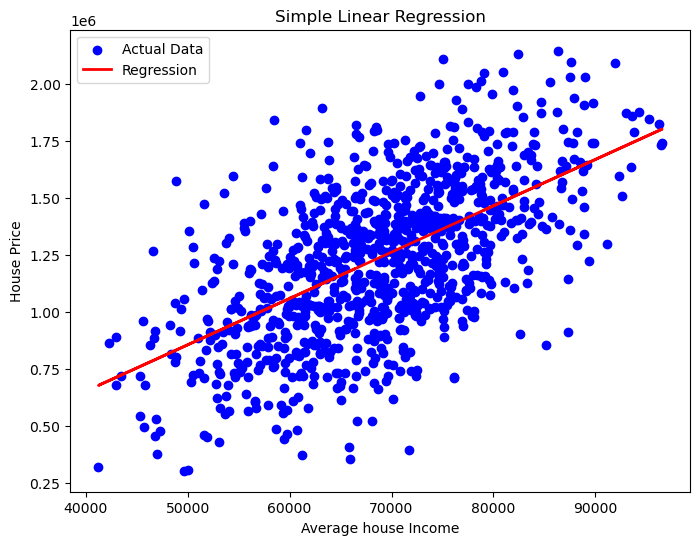

In [106]:
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test,color='blue',label='Actual Data')
plt.plot(X_test,y_pred,color='red',linewidth=2,label='Regression')
plt.xlabel("Average house Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [122]:
income = float(input("Enter Average Area Income:"))
new_data = np.array([[income]])
prediction = slr_model.predict(new_data)
print("Predicted House Price= ${:.2f}".format(prediction[0][0]))

Enter Average Area Income: 40000


Predicted House Price= $651823.91


C:\Users\cse\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
